## n-gram
At bag of words model, we classify news articles. We created a vocabulary of individual words or tokens, and then we counted words in each of these articles. But we are missing an important point which is in a language the order of words is important. And here in this model, we are just counting individual words but we are not capturing the relationship between the words.

**Basically, in a language the meaning of sentence is determined by order of the words**
So if there is some way to capture the order of the words in our model, that would be useful. So again in bag of words model what we did is individual tokens or individual words. But what if instead of individual words we capture pair of words. So it's like a moving window.

![n-gram](/media/elham/Learning/NLP/n-gram.jpg)

The generic term for this is n-gram. So you can have 4-gram, 5-gram and so on. And when you look at these bi-gram, tri-gram and so on, you see some meaningful words. The bag of words is a special case of bag of n-grams.

So here I have three documents and in NLP generally document means a text, a paragraph, a news article, all of these are called documents. If you have to build a bag of words model, the general approach is you do some pre-processing. You remove stop words and you do lemmetization, and then you get these kind of clean text or post process text.

![n-gram](/media/elham/Learning/NLP/n-gram2.jpg)

So I just combined basically, single bag of words, and bi-grams, and here what happens is now when you look at doc 1
and dock 3, you will see a lot of similarity. See Thor ate pizza, Loki ate pizza, kind of similar. you can see that by using single 1-gram and bi-gram, you can create more meaningful representation of your text.

![n-gram](/media/elham/Learning/NLP/n-gram3.jpg)

## limitation of n-gram model

**- as n increased, the dimensionality or sparsity increases**

In reality, your universe will be hundreds of news articles, or hundreds of books. The vocabulary will be so long. so as your n-gram increases, the sparsity increases because see here we
have two grams. so as I said usual approach is one gram and two gram combined. Let's say you have three grams, then then it keeps on increasing. So your dimensionality and sparsity increase increases, which results in a more computation need and
performance hit, also the memory issues.

**- doesn't address out of vocabulary problem.**

While training a model, you train on a certain dataset. But when you do prediction, you get totally new words and it's now hard to represent that in a vector.

![lim](/media/elham/Learning/NLP/n-gram4.jpg)

Let's Start :))

In [5]:
# Bag of words:

import numpy as np
import pandas as pd
import spacy
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer


In [14]:
cv = CountVectorizer(ngram_range=(1, 1)) # default value for ngram_range is (1, 1) which is used for bag of words
cv.fit(["Saba Amiri is looking for a new job"])
cv.vocabulary_

{'saba': 6, 'amiri': 0, 'is': 2, 'looking': 4, 'for': 1, 'new': 5, 'job': 3}

In [15]:
cv = CountVectorizer(ngram_range=(1, 2)) # single and bigram token
cv.fit(["Saba Amiri is looking for a new job"])
cv.vocabulary_

{'saba': 11,
 'amiri': 0,
 'is': 4,
 'looking': 7,
 'for': 2,
 'new': 9,
 'job': 6,
 'saba amiri': 12,
 'amiri is': 1,
 'is looking': 5,
 'looking for': 8,
 'for new': 3,
 'new job': 10}

In [16]:
cv = CountVectorizer(ngram_range=(1, 3)) # single, bigram and trigram token
cv.fit(["Saba Amiri is looking for a new job"])
cv.vocabulary_  # token : index

{'saba': 15,
 'amiri': 0,
 'is': 6,
 'looking': 10,
 'for': 3,
 'new': 13,
 'job': 9,
 'saba amiri': 16,
 'amiri is': 1,
 'is looking': 7,
 'looking for': 11,
 'for new': 4,
 'new job': 14,
 'saba amiri is': 17,
 'amiri is looking': 2,
 'is looking for': 8,
 'looking for new': 12,
 'for new job': 5}

In [17]:
cv = CountVectorizer(ngram_range=(2, 2)) # only bigram
cv.fit(["Saba Amiri is looking for a new job"])
cv.vocabulary_

{'saba amiri': 5,
 'amiri is': 0,
 'is looking': 2,
 'looking for': 3,
 'for new': 1,
 'new job': 4}

In [21]:
nlp = spacy.load("en_core_web_sm")
text = "Saba, you are looking for a new job?"


def preprocess(text):
    doc = nlp(text)
    filtered_tokens = []
    for token in doc:
        if not (token.is_punct) or (token.is_stop):  # you can use if and continue
            filtered_tokens.append(token.lemma_)

    return " ".join(filtered_tokens)
preprocess(text)

'Saba you be look for a new job'

In [20]:
corpus = ["Saba like pizza!", "Pizza is delicious, is it?", "Saba am tall."]

corpus_processed = [preprocess(text) for text in corpus ]

corpus_processed

['Saba like pizza', 'Pizza be delicious be it', 'Saba be tall']

- The **fit(data)** method is used to compute the mean and std dev for a given feature to be used further for scaling.
- The **transform(data)** method is used to perform scaling using mean and std dev calculated using the .fit() method.
- The **fit_transform()** method does both fits and transform.

In [21]:
cv = CountVectorizer(ngram_range=(1,2))
cv.fit(corpus_processed) # create vocabulary
cv.vocabulary_

{'saba': 11,
 'like': 7,
 'pizza': 9,
 'saba like': 13,
 'like pizza': 8,
 'be': 0,
 'delicious': 4,
 'it': 6,
 'pizza be': 10,
 'be delicious': 1,
 'delicious be': 5,
 'be it': 2,
 'tall': 14,
 'saba be': 12,
 'be tall': 3}

In [ ]:
cv.transform(corpus_processed).toarray()  # convert text to vectors as in NLP, ML models require numbers, they do not process text

array([[0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 0, 1, 0, 1, 0],
       [2, 1, 1, 0, 1, 1, 1, 0, 0, 1, 1, 0, 0, 0, 0],
       [1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 1]])

In [23]:
# out of vocabulary: Nani is not in our vocab
cv.transform(["Nani like pizza"]).toarray()

array([[0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 0, 0, 0, 0, 0]])

see the following example to figure out how the vector would be created

![](/media/elham/Learning/NLP/n_gram5.jpg)

****
## Now Let's practise: News Classification model

In [6]:
news_df = pd.read_json("/media/elham/Learning/NLP/news_dataset.json") #news dataset from Kaggle

print(news_df.shape)
news_df.head()

(12695, 2)


,text,category
0,Watching Schrödinger's Cat Die University of C...,SCIENCE
1,WATCH: Freaky Vortex Opens Up In Flooded Lake,SCIENCE
2,Entrepreneurs Today Don't Need a Big Budget to...,BUSINESS
3,These Roads Could Recharge Your Electric Car A...,BUSINESS
4,Civilian 'Guard' Fires Gun While 'Protecting' ...,CRIME


In [7]:
news_df.category.value_counts() #imbalance data

category
BUSINESS    4254
SPORTS      4167
CRIME       2893
SCIENCE     1381
Name: count, dtype: int64

In [8]:
count = news_df.category.value_counts()

min_sample = count.min()
min_sample_class = count.idxmin()
print(min_sample)
print(min_sample_class)

1381
SCIENCE


In [9]:
# undersampling

df_business = news_df[news_df.category =="BUSINESS"].sample(min_sample, random_state=42)
df_sport = news_df[news_df.category =="SPORTS"].sample(min_sample, random_state=42)
df_crime = news_df[news_df.category =="CRIME"].sample(min_sample, random_state=42)
df_science = news_df[news_df.category =="SCIENCE"]
df_crime.shape

(1381, 2)

In [10]:
df_balanced = pd.concat([df_business, df_sport, df_crime, df_science], axis=0)  # Add dataframes row by row

df_balanced.category.value_counts()

category
BUSINESS    1381
SPORTS      1381
CRIME       1381
SCIENCE     1381
Name: count, dtype: int64

In [11]:
label = {"BUSINESS" : 0, "SPORTS" : 1, "CRIME" : 2, "SCIENCE" : 3}
df_balanced["category_num"] = df_balanced.category.map(label)
df_balanced.head()

,text,category,category_num
594,How to Develop the Next Generation of Innovato...,BUSINESS,0
3093,"Madoff Victims' Payout Nears $7.2 Billion, Tru...",BUSINESS,0
7447,Bay Area Floats 'Sanctuary In Transit Policy' ...,BUSINESS,0
10388,Microsoft Agrees To Acquire LinkedIn For $26.2...,BUSINESS,0
1782,"Inside A Legal, Multibillion Dollar Weed Market",BUSINESS,0


## Data preparation

In [12]:
from sklearn.model_selection import train_test_split

X = df_balanced.text
y = df_balanced.category_num
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=df_balanced.category_num
    )

Note : ``stratify = class_label``    Create equal number of samples from all the clases in train and test

#### explore data

In [13]:
X_train.shape

(4419,)

In [14]:
X_train.head()

6414     Arby's Employee Keeps Job After Refusing To Se...
5679     Rescuing the Artifacts of Space Calling all te...
4170     Women in Business Q&A: Sophie Delafontaine, Ar...
11310    5 Formalized Referral Systems to Grow Your Sal...
4595       New Study Of Killer Chimps Sparks Major Debate 
Name: text, dtype: object

In [15]:
y_train.value_counts()

category_num
0    1105
3    1105
1    1105
2    1104
Name: count, dtype: int64

## training process

In [3]:
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report

**Note : usually naive bayes model would be recommended for text-base problems**

In [ ]:
# bigram model
# classifier
clf = Pipeline([
    ('vectorizer', CountVectorizer()),
    ('model', MultinomialNB())
    ])

clf.fit(X_train, y_train)
y_pred = clf.predict(X_test)

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.78      0.92      0.84       276
           1       0.91      0.84      0.88       276
           2       0.90      0.89      0.90       277
           3       0.89      0.82      0.85       276

    accuracy                           0.87      1105
   macro avg       0.87      0.87      0.87      1105
weighted avg       0.87      0.87      0.87      1105



In [ ]:
# ngram model
clf = Pipeline([
    ('vectorizer', CountVectorizer(ngram_range=(1, 2))),
    ('model', MultinomialNB())
    ])

clf.fit(X_train, y_train)
y_pred = clf.predict(X_test)

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.72      0.93      0.81       276
           1       0.93      0.82      0.87       276
           2       0.90      0.87      0.89       277
           3       0.90      0.76      0.82       276

    accuracy                           0.85      1105
   macro avg       0.86      0.85      0.85      1105
weighted avg       0.86      0.85      0.85      1105



**Note : The model should be selected based on the problem. Here the performance of ngram model is lower than bigram.**

In [18]:
print(f"real categories : {y_test[:5]}")
print(f"predicted categories : {y_pred[:5]}")

real categories : 12446    2
3868     2
3301     0
11543    1
9501     0
Name: category_num, dtype: int64
predicted categories : [2 2 0 1 0]


## Train with preprocess data

In [ ]:
def preprocess(text):
    doc = nlp(text)
    filtered_tokens = []
    for token in doc:
        if not (token.is_punct) or (token.is_stop):  # you can use if and continue
            filtered_tokens.append(token.lemma_)

    return " ".join(filtered_tokens)
preprocess(text)

In [22]:
df_balanced["prep_text"] = df_balanced.text.apply(preprocess)
df_balanced.head()

,text,category,category_num,prep_text
594,How to Develop the Next Generation of Innovato...,BUSINESS,0,how to develop the Next Generation of Innovato...
3093,"Madoff Victims' Payout Nears $7.2 Billion, Tru...",BUSINESS,0,Madoff Victims Payout near $ 7.2 billion Trust...
7447,Bay Area Floats 'Sanctuary In Transit Policy' ...,BUSINESS,0,Bay Area Floats Sanctuary in Transit Policy to...
10388,Microsoft Agrees To Acquire LinkedIn For $26.2...,BUSINESS,0,Microsoft agree to acquire linkedin for $ 26.2...
1782,"Inside A Legal, Multibillion Dollar Weed Market",BUSINESS,0,inside a Legal Multibillion Dollar Weed Market


In [23]:
X = df_balanced.prep_text
y = df_balanced.category_num
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=df_balanced.category_num
    )

clf = Pipeline([
    ('vectorizer', CountVectorizer()),
    ('model', MultinomialNB())
    ])

clf.fit(X_train, y_train)
y_pred = clf.predict(X_test)

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.79      0.91      0.84       276
           1       0.92      0.83      0.87       276
           2       0.88      0.91      0.90       277
           3       0.89      0.82      0.85       276

    accuracy                           0.87      1105
   macro avg       0.87      0.87      0.87      1105
weighted avg       0.87      0.87      0.87      1105



**Note : sometimes preprocessing bring some benefit but there are some cases that preprocessing may deter the result**

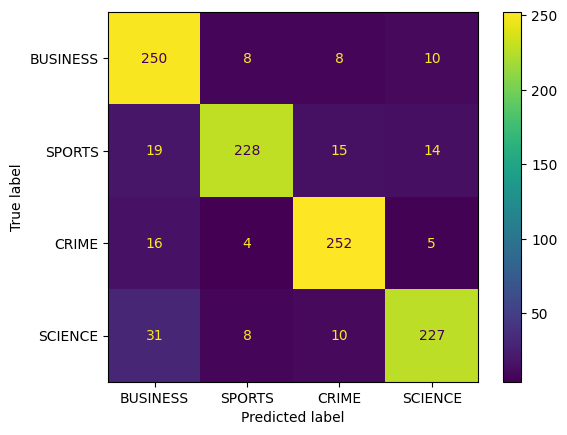

In [27]:
# confusion matrix

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=label)
disp.plot()